<a href="https://colab.research.google.com/github/donggeunlee77/R-exercise/blob/main/R-Poisson-Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Poisson regression with R

https://stats.oarc.ucla.edu/r/dae/poisson-regression/

In [1]:
install.packages("ggplot2")
install.packages("sandwich")
install.packages("msm")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zoo’


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘mvtnorm’, ‘expm’




In [2]:
library(ggplot2)
library(sandwich)
library(msm)

In [3]:
p <- read.csv("https://stats.idre.ucla.edu/stat/data/poisson_sim.csv")

prog is a categorical predictor variable with
three levels indicating the type of program in which the students were
enrolled. It is coded as 1 = “General”, 2 = “Academic” and 3 = “Vocational”

In [4]:
p <- within(p, {
    prog <- factor(prog, levels=1:3, labels=c("General","Academic","Vocational"))
      id <- factor(id)
})
nrow(p)

[1] 200

within()은 데이터프레임 내부의 변수를 수정하는 함수야.
- 첫 번째 p: 수정할 데이터프레임
- { }: 데이터프레임 내부에서 실행할 작업
- p <-: 수정된 결과를 다시 p에 저장

In [5]:
summary(p)

       id        num_awards           prog          math      
 1      :  1   Min.   :0.00   General   : 45   Min.   :33.00  
 2      :  1   1st Qu.:0.00   Academic  :105   1st Qu.:45.00  
 3      :  1   Median :0.00   Vocational: 50   Median :52.00  
 4      :  1   Mean   :0.63                    Mean   :52.65  
 5      :  1   3rd Qu.:1.00                    3rd Qu.:59.00  
 6      :  1   Max.   :6.00                    Max.   :75.00  
 (Other):194                                                  

In [6]:
with(p, tapply(num_awards, prog, function(x) {
  sprintf("M (SD) = %1.2f (%1.2f)", mean(x), sd(x))
}))

General               Academic             Vocational 
"M (SD) = 0.20 (0.40)" "M (SD) = 1.00 (1.28)" "M (SD) = 0.24 (0.52)"

with(p, ...) : 데이터프레임 p에 있는 변수를 사용할 때 매번 p$변수명이라고 쓰지 않아도 되도록 해주는 함수야.

예를들어 mean(p$num_awards) 와 with(p, mean(num_awards))는 동일한 결과를 냄.

tapply() : 특정 변수를 다른 변수의 범주에 따라 나누어 함수를 적용하는 함수. tapply(X, Index, Fun) 으로 구성되어있고 X 는 통계량을 계산할 대상변수, Index는 집단을 구분하는 변수, Fun은 각 집단에 적용할 함수

function(x) {} : 사용자 정의 함수.
sprintf() : 결과를 문자열로 출력. %1.2f는 f는 실수, .2는 소수점 이하 두자리까지 표시, 1은 최소 출력 너비 1자리.

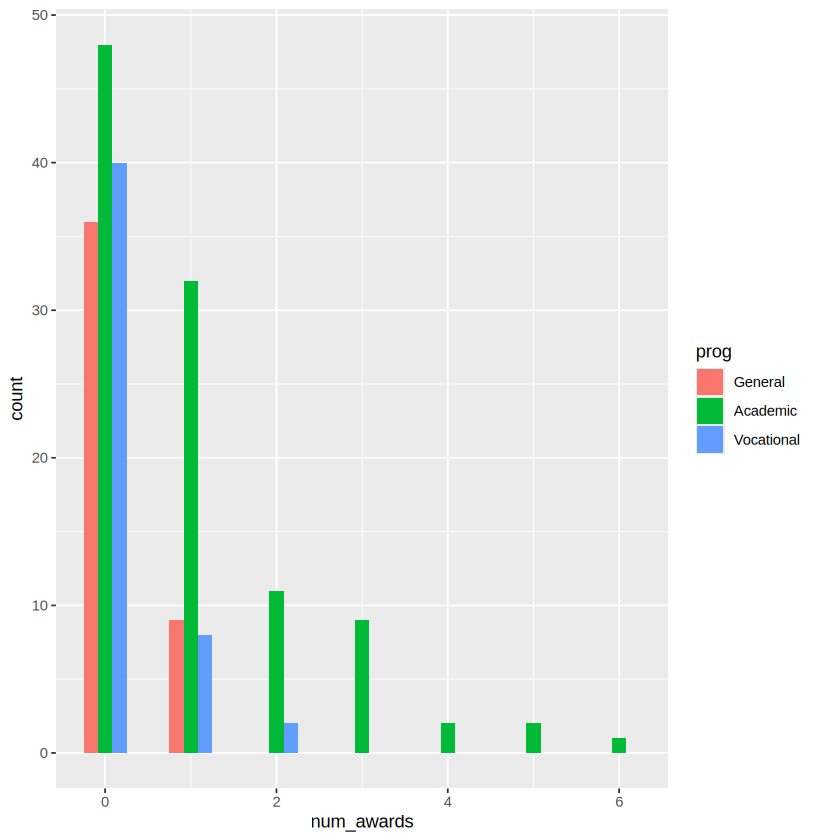

In [7]:
ggplot(p, aes(num_awards, fill=prog))+
  geom_histogram(binwidth=.5, position="dodge")

In [9]:
m1 <- glm(num_awards ~ prog + math, family="poisson", data=p)
m1


Call:  glm(formula = num_awards ~ prog + math, family = "poisson", data = p)

Coefficients:
   (Intercept)    progAcademic  progVocational            math  
      -5.24712         1.08386         0.36981         0.07015  

Degrees of Freedom: 199 Total (i.e. Null);  196 Residual
Null Deviance:	    287.7 
Residual Deviance: 189.4 	AIC: 373.5

In [10]:
summary(m1)


Call:
glm(formula = num_awards ~ prog + math, family = "poisson", data = p)

Coefficients:
               Estimate Std. Error z value Pr(>|z|)    
(Intercept)    -5.24712    0.65845  -7.969 1.60e-15 ***
progAcademic    1.08386    0.35825   3.025  0.00248 ** 
progVocational  0.36981    0.44107   0.838  0.40179    
math            0.07015    0.01060   6.619 3.63e-11 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 287.67  on 199  degrees of freedom
Residual deviance: 189.45  on 196  degrees of freedom
AIC: 373.5

Number of Fisher Scoring iterations: 6


In [13]:
cov.m1 <- vcovHC(m1, type="HC0")
std.err <- sqrt(diag(cov.m1))
r.est <- cbind(Estimate=coef(m1),
  "Robust SE" = std.err,
  "PR(>|z|)" = 2 * pnorm(abs(coef(m1)/std.err), lower.tail=FALSE),
  LL = coef(m1) - 1.96 * std.err,
  UL = coef(m1) + 1.96 * std.err)

In [14]:
r.est

,Estimate,Robust SE,PR(>|z|),LL,UL
(Intercept),-5.2471244,0.64599839,4.566630e-16,-6.51328124,-3.98096756
progAcademic,1.0838591,0.32104816,7.354745e-04,0.45460476,1.71311353
progVocational,0.3698092,0.40041731,3.557157e-01,-0.41500870,1.15462716
math,0.0701524,0.01043516,1.783975e-11,0.04969947,0.09060532


In [15]:
with(m1, cbind(Res.deviance = deviance,
  df = df.residual,
  p = pchisq(deviance, df.residual, lower.tail=FALSE)))

Res.deviance,df,p
189.4496,196,0.6182274


Likelihood 기반의 goodness-of-fit test는 D = 2(LLsaturated - LLfit) 통계량을 활용하고 이는 카이제곱분포를 따른다고 함.
Saturated model과 비교해서 유의미한 차이가 없이 데이터를 적절히 잘 설명한다는 결론이 나오면 좋은건데 즉, p value를 계산했는데, 이게 <0.05로 귀무가설이 기각되고 포화모형과 유의미한 차이가 있는거면 do not fit, >=0.05면 fit임.
여기 결과 0.618이니까 fit 하다, 데이터를 잘 설명해준다고 하는것.

다음은 prog 의 overall effect를 test하기 위해 prog 있는모델과 없는 모델을 비교할수 있음. 우도비검정(Likelihood ratio test) 혹은 AIC 비교를 통해 가능.

In [16]:
m2 <- update(m1, .~. - prog)
summary(m2)


Call:
glm(formula = num_awards ~ math, family = "poisson", data = p)

Coefficients:
             Estimate Std. Error z value Pr(>|z|)    
(Intercept) -5.333532   0.591261  -9.021   <2e-16 ***
math         0.086166   0.009679   8.902   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

(Dispersion parameter for poisson family taken to be 1)

    Null deviance: 287.67  on 199  degrees of freedom
Residual deviance: 204.02  on 198  degrees of freedom
AIC: 384.08

Number of Fisher Scoring iterations: 6


In [17]:
anova(m2, m1, test="Chisq")

,Resid. Df,Resid. Dev,Df,Deviance,Pr(>Chi)
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1,198,204.0213,NA,NA,NA
2,196,189.4496,2,14.57168,0.0006851718


아하 prog는 statistically significant predictor of num_awards가 맞구나!

다음은 Incident Rate Ratio (IRR) 확인하기

In [18]:
s <- deltamethod(list(~ exp(x1), ~ exp(x2), ~ exp(x3), ~ exp(x4)), coef(m1), cov.m1)

In [19]:
rexp.est <- exp(r.est[,-3])
rexp.est[, "Robust SE"] <- s

In [20]:
rexp.est

,Estimate,Robust SE,LL,UL
(Intercept),0.00526263,0.00339965,0.001483604,0.01866757
progAcademic,2.95606545,0.94903937,1.575550534,5.54620292
progVocational,1.44745846,0.57958742,0.660334536,3.17284023
math,1.07267164,0.01119351,1.050955210,1.09483681


여기 나온 Estimate가 IRR이다.

다음은 math가 평균값이라고 가정했을 때 expected marginal means 을 보고싶을때

In [21]:
s1 <- data.frame(math = mean(p$math), prog = factor(1:3, levels=1:3, labels=levels(p$prog)))
s1

math,prog
<dbl>,<fct>
52.645,General
52.645,Academic
52.645,Vocational


In [22]:
predict(m1, s1, type="response", se.fit=TRUE)

$fit
        1         2         3 
0.2114109 0.6249446 0.3060086 

$se.fit
         1          2          3 
0.07050108 0.08628117 0.08833706 

$residual.scale
[1] 1

s1은 예측에 사용할 새로운 데이터

type="response"는 원래 종속변수 척도로 예측값 반환. 즉 포아송회귀는 일반적으로 log척도가 선형예측값이라 type='link'를 하면 log 척도의 예측값을 반환해주지만, type='response'로 하면 지수함수를 적용하여 원래 척도인 예상 발생 건수를 반환해줌

se.fit=TRE 는 예측값의 표준오차도 함께 반

math가 평균값일 때 level 1은 약 0.21, level 2는 약 0.62, level 3은 약 0.31의 predicted number of events 를 알려주고, 쟤들의 비율이 IRR

In [25]:
p$phat <- predict(m1, type="response") ## predicted values를 phat에 저
p <- p[with(p, order(prog, math)),]
p

,id,num_awards,prog,math,phat
,<fct>,<int>,<fct>,<int>,<dbl>
105,167,0,General,35,0.06131134
16,134,0,General,39,0.08117233
48,111,0,General,39,0.08117233
2,108,0,General,41,0.09339886
74,70,0,General,41,0.09339886
6,51,0,General,42,0.10018631
21,109,0,General,42,0.10018631
31,25,0,General,42,0.10018631
58,175,1,General,42,0.10018631


Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


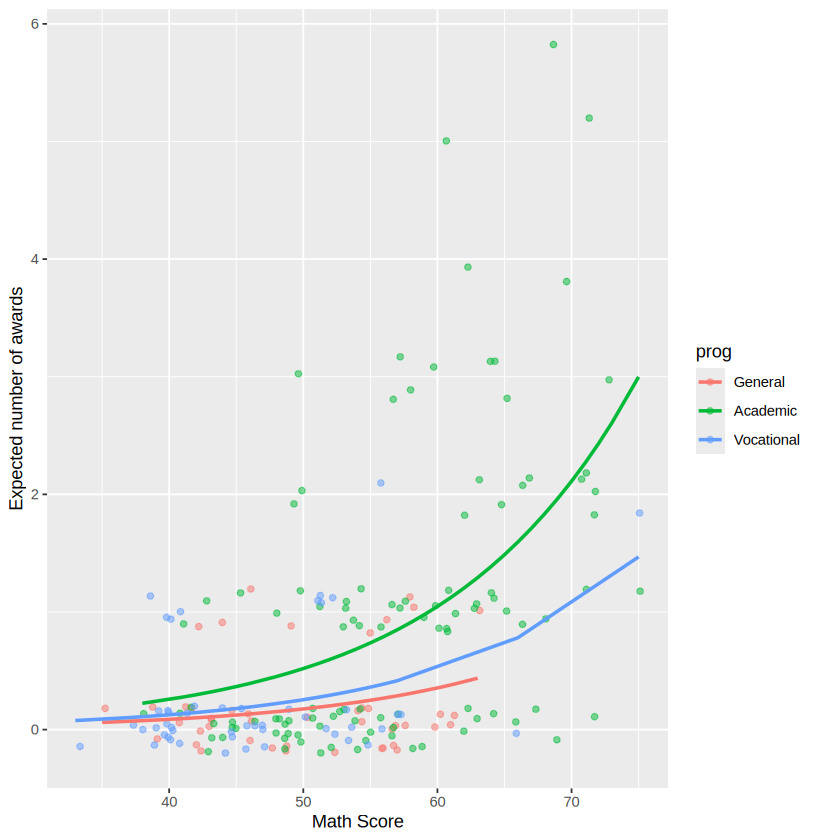

In [26]:
ggplot(p, aes(x = math, y = phat, colour = prog))+
  geom_point(aes(y = num_awards), alpha=0.5, position=position_jitter(h=0.2)) +
  geom_line(size = 1) +
  labs(x = "Math Score", y = "Expected number of awards")